# **Self-Adaptive POMDP.**

Après les modèles MDP et RL, on passe au POMDP car, dans un cas réel, l’état exact de l’utilisateur n’est pas toujours directement observable.
Au lieu de connaître avec certitude si l’utilisateur est Low, Medium ou High, le système maintient une distribution de probabilité appelée belief state.

Le POMDP permet donc de prendre une décision marketing sous incertitude :

belief → action → observation → mise à jour du belief → nouvelle action

L’objectif est de rendre le système auto-adaptatif : il ajuste ses actions selon les observations reçues et le niveau de confiance dans l’état utilisateur.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

BUYS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-buys.dat"
# ============================================================
# RELOAD CLICKS FOR HMM
# ============================================================

import pandas as pd

CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

print("Chargement clicks...")

clicks = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "category"],
    dtype={
        "session_id": "int64",
        "item_id": "string",
        "category": "string"
    },
    low_memory=False
)

# timestamps
clicks["timestamp"] = pd.to_datetime(
    clicks["timestamp"],
    errors="coerce",
    utc=True
)

clicks = clicks.dropna(subset=["timestamp"])

# ============================================================
# SAMPLE 100000 SESSIONS
# ============================================================

sessions = clicks["session_id"].unique()[:100000]

clicks = clicks[
    clicks["session_id"].isin(sessions)
]

print("Clicks shape:", clicks.shape)

clicks.head()

Mounted at /content/drive
Chargement clicks...
Clicks shape: (395698, 4)


,session_id,timestamp,item_id,category
0,1,2014-04-07 10:51:09.277000+00:00,214536502,0
1,1,2014-04-07 10:54:09.868000+00:00,214536500,0
2,1,2014-04-07 10:54:46.998000+00:00,214536506,0
3,1,2014-04-07 10:57:00.306000+00:00,214577561,0
4,2,2014-04-07 13:56:37.614000+00:00,214662742,0


===== Résultats POMDP =====


,Step,Real_state,Observation,Action,Most_likely_state,Max_belief
0,0,Low_Normal,Low_Normal,nothing,Low_Normal,0.2273
1,1,Low_Normal,Medium_Normal,nothing,Medium_Normal,0.3571
2,2,Medium_Normal,High_Normal,promo,High_Normal,0.4935
3,3,Medium_Normal,Medium_Normal,rec,High_Normal,0.4363
4,4,Medium_Normal,Medium_Fast,rec,Medium_Normal,0.5977
5,5,Medium_Normal,Low_Fast,nothing,Low_Normal,0.3343
6,6,Medium_Normal,Medium_Slow,nothing,Medium_Normal,0.5271
7,7,High_Normal,Medium_Fast,promo,Medium_Normal,0.4699
8,8,High_Normal,High_Normal,promo,High_Normal,0.4672
9,9,High_Normal,High_Normal,rec,High_Normal,0.6346



===== Belief final =====


,0
High_Normal,0.651570
Low_Normal,0.167520
Medium_Normal,0.098394
High_Fast,0.044186
Low_Slow,0.015672
High_Slow,0.010049
Medium_Fast,0.006792
Medium_Slow,0.003257
Low_Fast,0.002559


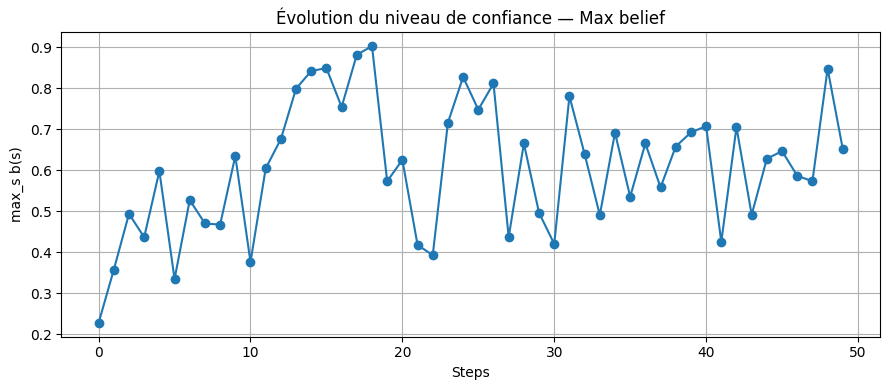

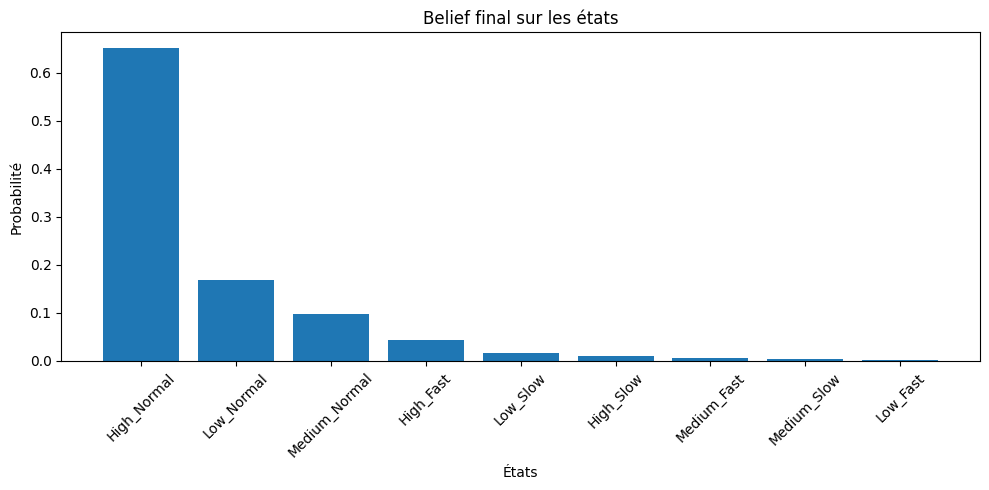

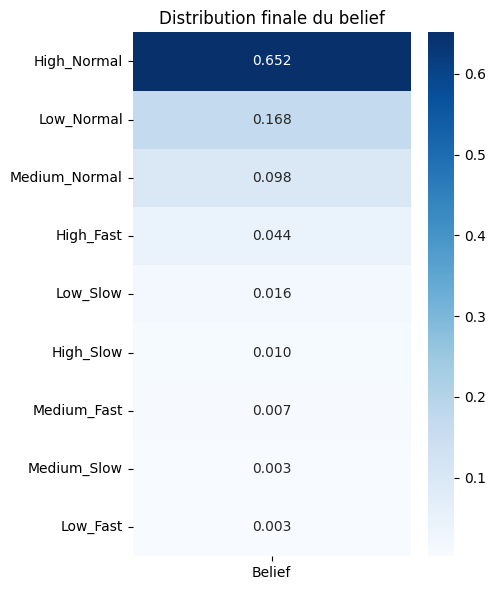

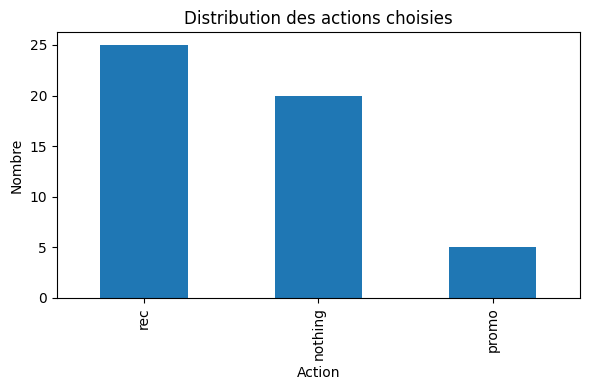

In [ ]:
# =========================================
# SELF-ADAPTIVE POMDP — VERSION COLAB COMPLETE
# =========================================

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns

random.seed(42)
np.random.seed(42)

# ===============================
# 1. États, actions et observations
# ===============================

states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

actions = ["pub", "promo", "rec", "nothing"]

observations = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

# ===============================
# 2. Transitions de base P(s'|s)
# ===============================

P_base = {
    "Low_Fast": {"Low_Fast": 0.60, "Medium_Fast": 0.30, "High_Fast": 0.10},
    "Low_Normal": {"Low_Normal": 0.65, "Medium_Normal": 0.25, "High_Normal": 0.10},
    "Low_Slow": {"Low_Slow": 0.70, "Medium_Slow": 0.20, "High_Slow": 0.10},

    "Medium_Fast": {"Medium_Fast": 0.60, "High_Fast": 0.25, "Low_Fast": 0.15},
    "Medium_Normal": {"Medium_Normal": 0.65, "High_Normal": 0.20, "Low_Normal": 0.15},
    "Medium_Slow": {"Medium_Slow": 0.70, "High_Slow": 0.14, "Low_Slow": 0.16},

    "High_Fast": {"High_Fast": 0.80, "Medium_Fast": 0.20},
    "High_Normal": {"High_Normal": 0.82, "Medium_Normal": 0.18},
    "High_Slow": {"High_Slow": 0.85, "Medium_Slow": 0.15}
}

# ===============================
# 3. Construire P(s'|s,a)
# ===============================

def normalize_dict(d):
    total = sum(d.values())
    if total == 0:
        return d
    return {k: v / total for k, v in d.items()}

def build_P_with_actions(P_base):
    P_actions = {}

    for a in actions:
        P_actions[a] = {}

        for s in states:
            probs = P_base[s].copy()

            if a == "pub" and s.startswith("Low"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("Medium"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "promo" and s.startswith("Medium"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            if a == "rec" and s.startswith("High"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.10
                    elif s_next.startswith("Medium"):
                        probs[s_next] = max(0, probs[s_next] - 0.10)

            P_actions[a][s] = normalize_dict(probs)

    return P_actions

P_actions = build_P_with_actions(P_base)

# ===============================
# 4. Récompenses normalisées
# ===============================

def build_rewards(scale=100):
    state_value = {
        "Low_Fast": 0,
        "Low_Normal": -5,
        "Low_Slow": -10,

        "Medium_Fast": 20,
        "Medium_Normal": 10,
        "Medium_Slow": 5,

        "High_Fast": 100,
        "High_Normal": 70,
        "High_Slow": 40
    }

    action_cost = {
        "pub": -2,
        "promo": -5,
        "rec": -1,
        "nothing": 0
    }

    R = {}

    for s in states:
        R[s] = {}

        for a in actions:
            reward = state_value[s] + action_cost[a]

            if s == "Medium_Slow" and a == "promo":
                reward += 20

            R[s][a] = reward / scale

    return R

R = build_rewards()

# ===============================
# 5. Modèle d'observation Z(o|s)
# ===============================

def build_observation_model(states, observations):
    Z = {}

    for s in states:
        Z[s] = {}

        state_level = s.split("_")[0]
        state_speed = s.split("_")[1]

        weights = {}

        for o in observations:
            obs_level = o.split("_")[0]
            obs_speed = o.split("_")[1]

            weight = 1.0

            if obs_level == state_level:
                weight += 4.0

            if obs_speed == state_speed:
                weight += 2.0

            weights[o] = weight

        total = sum(weights.values())

        for o in observations:
            Z[s][o] = weights[o] / total

    return Z

Z = build_observation_model(states, observations)

# ===============================
# 6. Belief state
# ===============================

def init_belief(states):
    return {s: 1 / len(states) for s in states}

def normalize_belief(b):
    total = sum(b.values())

    if total <= 0:
        return init_belief(list(b.keys()))

    return {s: b[s] / total for s in b}

# ===============================
# 7. Mise à jour du belief
# ===============================

def update_belief(belief, action, observation, P, Z):
    new_belief = {}

    for s_next in states:
        prediction = 0.0

        for s in states:
            if s_next in P[action][s]:
                prediction += P[action][s][s_next] * belief[s]

        correction = Z[s_next].get(observation, 1e-9)

        new_belief[s_next] = correction * prediction

    return normalize_belief(new_belief)

# ===============================
# 8. Sélection d'action adaptative
# ===============================

def choose_action_from_belief(belief, P, R, gamma=0.5):
    best_action = None
    best_value = -np.inf

    for a in actions:
        value = 0.0

        for s in states:
            immediate = R[s][a]

            future = 0.0
            for s_next, prob in P[a][s].items():
                future += prob * max(R[s_next].values())

            value += belief[s] * (immediate + gamma * future)

        if value > best_value:
            best_value = value
            best_action = a

    return best_action

# ===============================
# 9. Environnement POMDP
# ===============================

def step_environment(P, current_state, action, Z):
    next_states = list(P[action][current_state].keys())
    probs = list(P[action][current_state].values())

    next_state = random.choices(next_states, weights=probs, k=1)[0]

    obs_list = list(Z[next_state].keys())
    obs_probs = list(Z[next_state].values())

    observation = random.choices(obs_list, weights=obs_probs, k=1)[0]

    return next_state, observation

# ===============================
# 10. Simulation POMDP
# ===============================

def run_pomdp(P, R, Z, steps=50):
    belief = init_belief(states)
    current_state = random.choice(states)

    history = []
    rows = []

    for t in range(steps):
        action = choose_action_from_belief(belief, P, R)

        current_state, observation = step_environment(
            P,
            current_state,
            action,
            Z
        )

        belief = update_belief(
            belief,
            action,
            observation,
            P,
            Z
        )

        max_belief = max(belief.values())
        most_likely_state = max(belief, key=belief.get)

        history.append(max_belief)

        rows.append({
            "Step": t,
            "Real_state": current_state,
            "Observation": observation,
            "Action": action,
            "Most_likely_state": most_likely_state,
            "Max_belief": round(max_belief, 4)
        })

    return belief, history, pd.DataFrame(rows)

# ===============================
# 11. Exécution
# ===============================

final_belief, belief_history, pomdp_results = run_pomdp(
    P_actions,
    R,
    Z,
    steps=50
)

print("===== Résultats POMDP =====")
display(pomdp_results.head(20))

print("\n===== Belief final =====")
final_belief_df = pd.Series(final_belief).sort_values(ascending=False)
display(final_belief_df)

# ===============================
# 12. Visualisations
# ===============================

plt.figure(figsize=(9, 4))
plt.plot(belief_history, marker="o")
plt.title("Évolution du niveau de confiance — Max belief")
plt.xlabel("Steps")
plt.ylabel("max_s b(s)")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(final_belief_df.index, final_belief_df.values)
plt.title("Belief final sur les états")
plt.xlabel("États")
plt.ylabel("Probabilité")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Heatmap belief final
plt.figure(figsize=(5, 6))
sns.heatmap(
    final_belief_df.to_frame(name="Belief"),
    annot=True,
    fmt=".3f",
    cmap="Blues"
)
plt.title("Distribution finale du belief")
plt.tight_layout()
plt.show()

# Actions choisies
plt.figure(figsize=(6, 4))
pomdp_results["Action"].value_counts().plot(kind="bar")
plt.title("Distribution des actions choisies")
plt.xlabel("Action")
plt.ylabel("Nombre")
plt.tight_layout()
plt.show()

Les résultats du POMDP montrent que le belief state évolue progressivement à partir des observations partielles. Au début, le modèle présente une forte incertitude, puis la confiance augmente au fil des observations. Le belief final indique une probabilité dominante pour l’état High_Normal, ce qui conduit le système à privilégier des actions de recommandation. Le POMDP permet ainsi de modéliser un système marketing adaptatif capable de prendre des décisions sous incertitude.

# **Deep POMDP avec mémoire récurrente (GRU)**

Le POMDP classique utilise explicitement un belief state probabiliste afin d’estimer l’état réel du système à partir des observations partielles. Cependant, lorsque les séquences deviennent longues et complexes, le calcul exact du belief devient difficile.

Pour résoudre ce problème, on utilise un :

Deep POMDP

basé sur un réseau neuronal récurrent :

GRU (Gated Recurrent Unit)

Le GRU permet au modèle de mémoriser l’historique des observations et de construire implicitement une représentation cachée de l’état utilisateur.

Ainsi, le système apprend directement :

observation → mémoire → action optimale

sans calcul explicite du belief Bayesien.

Le GRU apprend

h
t
	​

=GRU(h
t−1
	​

,o
t
	​

)

Donc :

o
t
	​

 = observation
h
t
	​

 = mémoire cachée
Puis le réseau prédit :

Q(h
t
	​

,a)

Donc :

état caché implicite
action optimale

Device: cuda
Episode 0 | Reward = 18
Episode 50 | Reward = 120
Episode 100 | Reward = 138
Episode 150 | Reward = 137
Episode 200 | Reward = 154
Episode 250 | Reward = 184
Episode 300 | Reward = 164
Episode 350 | Reward = 196
Episode 400 | Reward = 215
Episode 450 | Reward = 199

===== TEST POLICY =====

===== Test séquentiel =====


,Step,State,Action
0,0,Medium_Normal,promo
1,1,High_Normal,rec
2,2,Low_Slow,pub
3,3,Low_Slow,pub
4,4,High_Slow,rec
5,5,Low_Slow,pub
6,6,Medium_Slow,promo
7,7,High_Fast,rec
8,8,Low_Normal,pub
9,9,Low_Slow,pub



===== POLICY ANALYSIS =====


,State,Best_action,Q_pub,Q_promo,Q_rec,Q_nothing
0,Low_Slow,pub,71.421776,64.988213,61.024704,63.617943
1,Low_Normal,pub,71.379906,65.169731,61.089523,63.683147
2,Low_Fast,pub,71.532616,64.975685,61.207443,63.721916
3,Medium_Slow,promo,67.157982,72.095825,65.094063,65.097290
4,Medium_Normal,promo,67.193443,72.132126,64.980202,65.077698
5,Medium_Fast,promo,67.185875,72.106308,65.358795,65.189857
6,High_Slow,rec,61.598022,63.324184,76.555092,63.595276
7,High_Normal,rec,61.644760,63.302212,76.570412,63.608795
8,High_Fast,rec,61.561684,63.266842,77.043442,63.697590


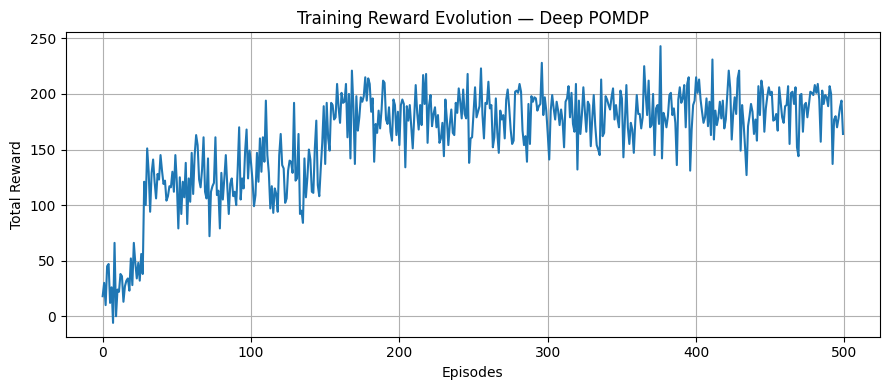

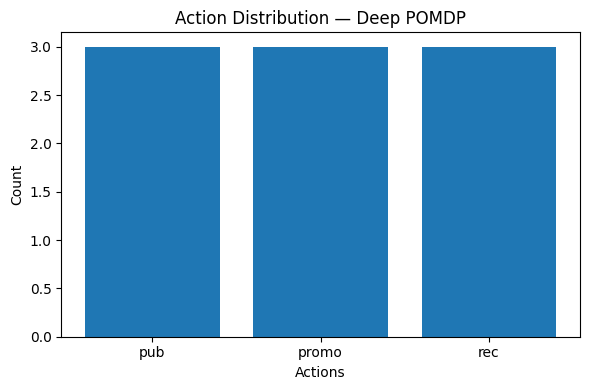

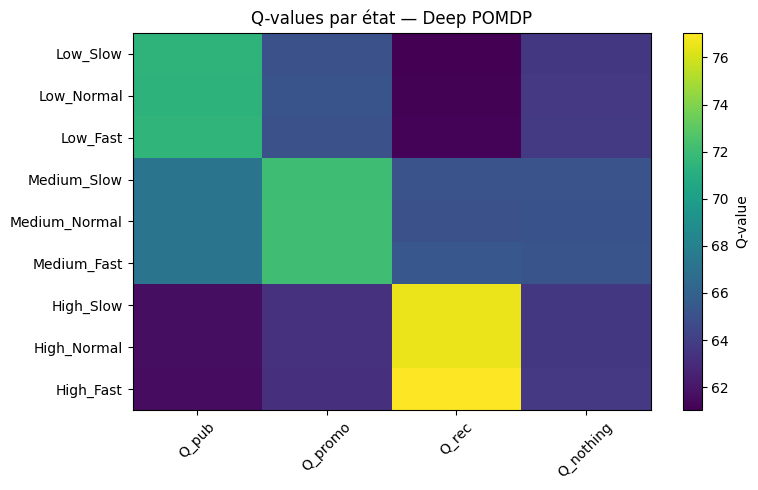

In [ ]:
# =========================================
# DEEP POMDP — VERSION COLAB COMPLETE
# =========================================

import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# ===============================
# 1. États et actions
# ===============================

actions = ["pub", "promo", "rec", "nothing"]
n_actions = len(actions)

states = [
    "Low_Slow", "Low_Normal", "Low_Fast",
    "Medium_Slow", "Medium_Normal", "Medium_Fast",
    "High_Slow", "High_Normal", "High_Fast"
]

# ===============================
# 2. Encodage observation
# ===============================

def encode_observation(obs):
    level = ["Low", "Medium", "High"]
    speed = ["Slow", "Normal", "Fast"]

    parts = obs.split("_")

    vec = np.zeros(6)
    vec[level.index(parts[0])] = 1
    vec[3 + speed.index(parts[1])] = 1

    return torch.tensor(vec, dtype=torch.float32)

# ===============================
# 3. Modèle Deep POMDP avec GRU
# ===============================

class DeepPOMDP(nn.Module):
    def __init__(self):
        super().__init__()

        self.gru = nn.GRU(
            input_size=6,
            hidden_size=64,
            batch_first=True
        )

        self.fc = nn.Linear(64, n_actions)

    def forward(self, x, h):
        out, h = self.gru(x, h)
        q = self.fc(out[:, -1, :])
        return q, h

# ===============================
# 4. Environnement simulé
# ===============================

def random_transition(state):
    return random.choice(states)

def reward_function(state, action):
    level = state.split("_")[0]

    if level == "High" and action == "rec":
        return 10
    elif level == "Medium" and action == "promo":
        return 7
    elif level == "Low" and action == "pub":
        return 5
    else:
        return -1

# ===============================
# 5. Entraînement
# ===============================

def train_deep_pomdp(
    episodes=500,
    steps_per_episode=30,
    gamma=0.9,
    epsilon=0.2,
    lr=0.001
):
    model = DeepPOMDP().to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    reward_history = []

    for ep in range(episodes):

        state = random.choice(states)
        h = torch.zeros(1, 1, 64).to(device)

        total_reward = 0

        for t in range(steps_per_episode):

            obs = encode_observation(state).to(device).view(1, 1, -1)

            q_values, h = model(obs, h.detach())

            if random.random() < epsilon:
                action_idx = random.randint(0, n_actions - 1)
            else:
                action_idx = torch.argmax(q_values).item()

            action = actions[action_idx]

            next_state = random_transition(state)
            reward = reward_function(state, action)

            total_reward += reward

            next_obs = encode_observation(next_state).to(device).view(1, 1, -1)

            with torch.no_grad():
                next_q, _ = model(next_obs, h.detach())
                target = reward + gamma * torch.max(next_q)

            target_q = q_values.clone().detach()
            target_q[0, action_idx] = target

            loss = criterion(q_values, target_q)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            state = next_state

        reward_history.append(total_reward)

        if ep % 50 == 0:
            print(f"Episode {ep} | Reward = {total_reward}")

    return model, reward_history

# ===============================
# 6. Test policy
# ===============================

def test_policy(model, steps=20):
    print("\n===== TEST POLICY =====")

    state = random.choice(states)
    h = torch.zeros(1, 1, 64).to(device)

    rows = []

    for t in range(steps):
        obs = encode_observation(state).to(device).view(1, 1, -1)

        q_values, h = model(obs, h.detach())

        action_idx = torch.argmax(q_values).item()
        action = actions[action_idx]

        rows.append({
            "Step": t,
            "State": state,
            "Action": action
        })

        state = random_transition(state)

    return pd.DataFrame(rows)

# ===============================
# 7. Analyse politique par état
# ===============================

def analyze_policy(model):
    action_counts = Counter()
    rows = []

    for state in states:
        obs = encode_observation(state).to(device).view(1, 1, -1)
        h = torch.zeros(1, 1, 64).to(device)

        q_values, _ = model(obs, h)

        action_idx = torch.argmax(q_values).item()
        action = actions[action_idx]

        action_counts[action] += 1

        rows.append({
            "State": state,
            "Best_action": action,
            "Q_pub": q_values[0, 0].item(),
            "Q_promo": q_values[0, 1].item(),
            "Q_rec": q_values[0, 2].item(),
            "Q_nothing": q_values[0, 3].item()
        })

    return pd.DataFrame(rows), action_counts

# ===============================
# 8. Exécution
# ===============================

model, reward_history = train_deep_pomdp(
    episodes=500,
    steps_per_episode=30,
    gamma=0.9,
    epsilon=0.2,
    lr=0.001
)

test_df = test_policy(model, steps=20)
print("\n===== Test séquentiel =====")
display(test_df)

policy_df, action_counts = analyze_policy(model)

print("\n===== POLICY ANALYSIS =====")
display(policy_df)

# ===============================
# 9. Visualisations
# ===============================

plt.figure(figsize=(9, 4))
plt.plot(reward_history)
plt.title("Training Reward Evolution — Deep POMDP")
plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(action_counts.keys(), action_counts.values())
plt.title("Action Distribution — Deep POMDP")
plt.xlabel("Actions")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

q_cols = ["Q_pub", "Q_promo", "Q_rec", "Q_nothing"]

plt.figure(figsize=(8, 5))
plt.imshow(policy_df[q_cols], aspect="auto")
plt.colorbar(label="Q-value")
plt.xticks(range(len(q_cols)), q_cols, rotation=45)
plt.yticks(range(len(policy_df)), policy_df["State"])
plt.title("Q-values par état — Deep POMDP")
plt.tight_layout()
plt.show()

Episode 0 | Reward = 30
Episode 50 | Reward = 97
Episode 100 | Reward = 118
Episode 150 | Reward = 138
Episode 200 | Reward = 176
Episode 250 | Reward = 190
Episode 300 | Reward = 196
Episode 350 | Reward = 171
Episode 400 | Reward = 178
Episode 450 | Reward = 204


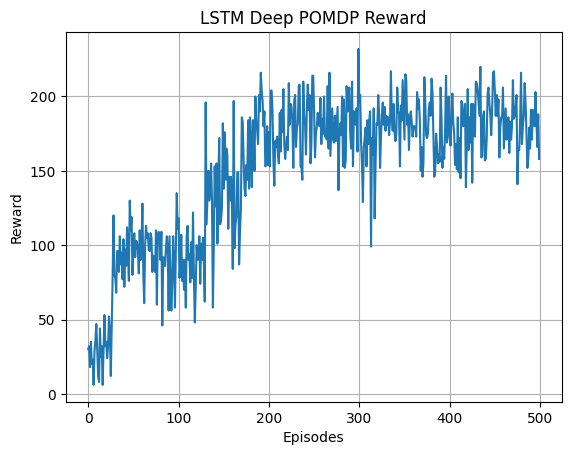

In [ ]:
# # =========================================
# DEEP POMDP (LSTM VERSION)
# =========================================

import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ===============================
# ACTIONS & STATES
# ===============================
actions = ["pub", "promo", "rec", "nothing"]
n_actions = len(actions)

states = [
    "Low_Slow", "Low_Normal", "Low_Fast",
    "Medium_Slow", "Medium_Normal", "Medium_Fast",
    "High_Slow", "High_Normal", "High_Fast"
]

# ===============================
# ENCODING
# ===============================
def encode(obs):

    level = ["Low", "Medium", "High"]
    speed = ["Slow", "Normal", "Fast"]

    parts = obs.split("_")

    x = np.zeros(6)
    x[level.index(parts[0])] = 1
    x[3 + speed.index(parts[1])] = 1

    return torch.tensor(x, dtype=torch.float32)

# ===============================
# MODEL LSTM
# ===============================
class DeepPOMDP_LSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(6, 64, batch_first=True)
        self.fc = nn.Linear(64, n_actions)

    def forward(self, x, h, c):

        out, (h, c) = self.lstm(x, (h, c))
        q = self.fc(out[:, -1, :])

        return q, h, c

# ===============================
# ENV
# ===============================
def random_transition(state):
    return random.choice(states)

def reward(state, action):

    level = state.split("_")[0]

    if level == "High" and action == "rec":
        return 10
    elif level == "Medium" and action == "promo":
        return 7
    elif level == "Low" and action == "pub":
        return 5
    else:
        return -1

# ===============================
# TRAIN
# ===============================
def train():

    model = DeepPOMDP_LSTM().to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.MSELoss()

    gamma = 0.9
    epsilon = 0.2
    episodes = 500

    rewards_hist = []

    for ep in range(episodes):

        state = random.choice(states)

        h = torch.zeros(1, 1, 64).to(device)
        c = torch.zeros(1, 1, 64).to(device)

        total = 0

        for _ in range(30):

            x = encode(state).to(device).view(1, 1, -1)

            q, h, c = model(x, h.detach(), c.detach())

            # policy
            if random.random() < epsilon:
                a_idx = random.randint(0, n_actions - 1)
            else:
                a_idx = torch.argmax(q).item()

            a = actions[a_idx]

            s_next = random_transition(state)
            r = reward(state, a)
            total += r

            x_next = encode(s_next).to(device).view(1, 1, -1)

            with torch.no_grad():
                q_next, _, _ = model(x_next, h.detach(), c.detach())
                target = r + gamma * torch.max(q_next)

            q_target = q.clone().detach()
            q_target[0, a_idx] = target

            loss = loss_fn(q, q_target)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            state = s_next

        rewards_hist.append(total)

        if ep % 50 == 0:
            print(f"Episode {ep} | Reward = {total}")

    return model, rewards_hist

# ===============================
# PLOT
# ===============================
def plot(rewards):

    plt.plot(rewards)
    plt.title("LSTM Deep POMDP Reward")
    plt.xlabel("Episodes")
    plt.ylabel("Reward")
    plt.grid()
    plt.show()

# ===============================
# MAIN
# ===============================
if __name__ == "__main__":

    model, rewards = train()
    plot(rewards)






Le reward augmente clairement :

30 → 97 → 118 → 176 → 190 → 204

Donc le modèle LSTM apprend progressivement une meilleure stratégie.

Lecture par phases

| Phase  | Épisodes | Interprétation                          |
| ------ | -------: | --------------------------------------- |
| Début  |    0–100 | exploration + apprentissage initial     |
| Milieu |  150–300 | amélioration forte de la politique      |
| Fin    |  350–450 | stabilisation autour de valeurs élevées |


Le petit recul à l’épisode 350 est normal : en RL, l’exploration et les transitions aléatoires créent des fluctuations.

Conclusion rapport

Les résultats du Deep POMDP basé sur LSTM montrent une amélioration progressive du reward au cours de l’apprentissage. Le modèle passe d’un reward initial de 30 à une valeur proche de 204 en fin d’entraînement, ce qui indique que l’agent apprend à exploiter l’historique des observations pour sélectionner des actions plus efficaces. Cette progression confirme l’intérêt de l’intégration d’une mémoire séquentielle avant le passage au NM-POMDP complet.

Le Deep POMDP basé sur un GRU montre une amélioration progressive du reward au cours de l’apprentissage. Le modèle apprend une politique cohérente avec le funnel marketing : publicité pour les utilisateurs Low, promotion pour les utilisateurs Medium et recommandation pour les utilisateurs High. Cela confirme que le réseau récurrent parvient à exploiter l’historique des observations pour prendre des décisions adaptées sous incertitude.

# **Non-Markovian POMDP**

In [ ]:
#!/usr/bin/env python3
"""
NM-POMDP (Non-Markovian POMDP) pour E-Commerce
Dataset: Yoochoose (RecSys Challenge 2015)

Version corrigée :
- LSTM NM-POMDP
- GRU + Attention NM-POMDP
- Transformer NM-POMDP
- Correction du problème : tuple returned by GRU_Attention
- Entraînement, évaluation et visualisation
"""

import os
import random
import pickle
from collections import deque

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm import tqdm


# ============================================================
# CONFIGURATION
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

OUTPUT_DIR = "/mnt/user-data/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 1. CHARGEMENT ET PRÉTRAITEMENT DES DONNÉES YOOCHOOSE
# ============================================================

class YoochooseProcessor:
    """Processeur pour le dataset Yoochoose."""

    def __init__(self, clicks_file="clicks.dat", buys_file="buys.dat", max_sessions=10000):
        self.clicks_file = clicks_file
        self.buys_file = buys_file
        self.max_sessions = max_sessions

        self.state_mapping = {
            "Low_N": 0, "Low_F": 1, "Low_S": 2,
            "Med_N": 3, "Med_F": 4, "Med_S": 5,
            "High_N": 6, "High_F": 7, "High_S": 8
        }

        self.action_mapping = {
            "pub": 0,
            "promo": 1,
            "rec": 2,
            "nothing": 3
        }

    def generate_synthetic_sessions(self):
        """Génère des sessions synthétiques pour démonstration."""
        sessions = []

        for i in range(self.max_sessions):
            session_length = np.random.randint(2, 16)
            observations = []

            for t in range(session_length):
                if t < session_length // 3:
                    obs = np.random.choice([0, 1, 2])
                elif t < 2 * session_length // 3:
                    obs = np.random.choice([3, 4, 5])
                else:
                    obs = np.random.choice([6, 7, 8])
                observations.append(obs)

            last_obs = observations[-1]

            if last_obs >= 6:
                buy = np.random.random() < 0.16
            elif last_obs >= 3:
                buy = np.random.random() < 0.09
            else:
                buy = np.random.random() < 0.06

            sessions.append({
                "session_id": i,
                "observations": observations,
                "buy": buy,
                "length": session_length
            })

        return sessions

    def create_episodes(self, sessions):
        """Convertit les sessions en épisodes RL."""
        episodes = []

        for session in sessions:
            obs_seq = session["observations"]
            buy = session["buy"]

            actions = []
            rewards = []

            for t, obs in enumerate(obs_seq):
                if obs < 3:
                    action = 0  # pub
                elif obs < 6:
                    action = 1  # promo
                else:
                    action = 2  # recommandation

                actions.append(action)

                if t == len(obs_seq) - 1:
                    reward = 100 if buy else -10
                else:
                    reward = -1

                rewards.append(reward)

            episodes.append({
                "observations": obs_seq,
                "actions": actions,
                "rewards": rewards,
                "buy": buy
            })

        return episodes


# ============================================================
# 2. MODÈLES NM-POMDP
# ============================================================

class LSTM_NM_POMDP(nn.Module):
    """LSTM-based Non-Markovian POMDP."""

    def __init__(self, obs_dim=9, action_dim=4, hidden_dim=128, num_layers=2):
        super().__init__()

        self.obs_dim = obs_dim
        self.action_dim = action_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.embedding = nn.Embedding(obs_dim, 64)

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.1 if num_layers > 1 else 0.0
        )

        self.q_network = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        )

    def forward(self, obs_sequence):
        embedded = self.embedding(obs_sequence)
        _, (h_n, _) = self.lstm(embedded)
        h_t = h_n[-1]
        q_values = self.q_network(h_t)
        return q_values


class GRU_Attention_NM_POMDP(nn.Module):
    """GRU + Attention Non-Markovian POMDP."""

    def __init__(self, obs_dim=9, action_dim=4, hidden_dim=128, num_layers=2):
        super().__init__()

        self.obs_dim = obs_dim
        self.action_dim = action_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.embedding = nn.Embedding(obs_dim, 64)

        self.gru = nn.GRU(
            input_size=64,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.1 if num_layers > 1 else 0.0
        )

        self.q_network = nn.Sequential(
            nn.Linear(hidden_dim * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        )

    def forward(self, obs_sequence):
        embedded = self.embedding(obs_sequence)
        gru_out, _ = self.gru(embedded)

        h_t = gru_out[:, -1, :]

        scores = torch.bmm(gru_out, h_t.unsqueeze(-1))
        alpha = F.softmax(scores, dim=1)

        context = torch.sum(alpha * gru_out, dim=1)
        combined = torch.cat([h_t, context], dim=-1)

        q_values = self.q_network(combined)

        # Important : ce modèle retourne deux valeurs.
        # L'agent doit donc récupérer uniquement q_values pour le DQN.
        return q_values, alpha


class PositionalEncoding(nn.Module):
    """Positional Encoding pour Transformer."""

    def __init__(self, d_model, max_len=100):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class TransformerNMPOMDP(nn.Module):
    """Transformer-based Non-Markovian POMDP."""

    def __init__(self, obs_dim=9, action_dim=4, d_model=128, nhead=8, num_layers=4):
        super().__init__()

        self.obs_dim = obs_dim
        self.action_dim = action_dim
        self.d_model = d_model
        self.nhead = nhead
        self.num_layers = num_layers

        self.embedding = nn.Embedding(obs_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=512,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.q_network = nn.Sequential(
            nn.Linear(d_model, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, action_dim)
        )

    def forward(self, obs_sequence):
        embedded = self.embedding(obs_sequence)
        embedded = self.pos_encoder(embedded)
        transformer_out = self.transformer(embedded)
        h_t = transformer_out[:, -1, :]
        q_values = self.q_network(h_t)
        return q_values


# ============================================================
# 3. AGENT DQN CORRIGÉ
# ============================================================

class DQNAgent:
    """Agent DQN pour NM-POMDP."""

    def __init__(self, model, action_dim=4, lr=1e-3, gamma=0.95):
        self.model = model.to(DEVICE)

        # Création correcte du target model avec les mêmes hyperparamètres.
        self.target_model = self._clone_model(model).to(DEVICE)
        self.target_model.load_state_dict(self.model.state_dict())
        self.target_model.eval()

        self.action_dim = action_dim
        self.gamma = gamma

        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=lr)
        self.criterion = nn.MSELoss()

        self.replay_buffer = deque(maxlen=50000)

        self.epsilon = 0.3
        self.epsilon_min = 0.05
        self.epsilon_decay = 0.995

    def _clone_model(self, model):
        """Clone le modèle avec ses paramètres principaux."""
        if isinstance(model, LSTM_NM_POMDP):
            return LSTM_NM_POMDP(
                obs_dim=model.obs_dim,
                action_dim=model.action_dim,
                hidden_dim=model.hidden_dim,
                num_layers=model.num_layers
            )

        if isinstance(model, GRU_Attention_NM_POMDP):
            return GRU_Attention_NM_POMDP(
                obs_dim=model.obs_dim,
                action_dim=model.action_dim,
                hidden_dim=model.hidden_dim,
                num_layers=model.num_layers
            )

        if isinstance(model, TransformerNMPOMDP):
            return TransformerNMPOMDP(
                obs_dim=model.obs_dim,
                action_dim=model.action_dim,
                d_model=model.d_model,
                nhead=model.nhead,
                num_layers=model.num_layers
            )

        raise ValueError("Type de modèle non reconnu.")

    def get_q_values(self, model, histories):
        """
        Corrige le problème du GRU + Attention.
        - LSTM retourne q_values
        - Transformer retourne q_values
        - GRU + Attention retourne (q_values, alpha)
        Donc on récupère toujours q_values.
        """
        output = model(histories)

        if isinstance(output, tuple):
            return output[0]

        return output

    def select_action(self, history, training=True):
        """Sélection d'action epsilon-greedy."""
        if training and np.random.random() < self.epsilon:
            return np.random.randint(self.action_dim)

        self.model.eval()
        with torch.no_grad():
            history_tensor = torch.LongTensor([history]).to(DEVICE)
            q_values = self.get_q_values(self.model, history_tensor)
            action = q_values.argmax(dim=-1).item()

        if training:
            self.model.train()

        return action

    def store_transition(self, history, action, reward, next_history, done):
        self.replay_buffer.append({
            "history": history,
            "action": action,
            "reward": reward,
            "next_history": next_history,
            "done": done
        })

    def update(self, batch_size=128):
        """Mise à jour du réseau DQN."""
        if len(self.replay_buffer) < batch_size:
            return None

        self.model.train()

        batch = random.sample(self.replay_buffer, batch_size)

        histories = torch.LongTensor([t["history"] for t in batch]).to(DEVICE)
        actions = torch.LongTensor([t["action"] for t in batch]).to(DEVICE)
        rewards = torch.FloatTensor([t["reward"] for t in batch]).to(DEVICE)
        next_histories = torch.LongTensor([t["next_history"] for t in batch]).to(DEVICE)
        dones = torch.FloatTensor([t["done"] for t in batch]).to(DEVICE)

        current_q_all = self.get_q_values(self.model, histories)
        current_q = current_q_all.gather(1, actions.unsqueeze(1)).squeeze(1)

        with torch.no_grad():
            next_q_all = self.get_q_values(self.target_model, next_histories)
            next_q = next_q_all.max(dim=1)[0]
            target_q = rewards + self.gamma * next_q * (1 - dones)

        loss = self.criterion(current_q, target_q)

        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
        self.optimizer.step()

        return loss.item()

    def update_target_network(self):
        self.target_model.load_state_dict(self.model.state_dict())

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)


# ============================================================
# 4. TRAINING
# ============================================================

def train_nm_pomdp(agent, episodes, num_epochs=8, batch_size=128, max_history=10):
    """Entraînement du NM-POMDP."""

    print("\n" + "=" * 60)
    print(f"Entraînement NM-POMDP - {agent.model.__class__.__name__}")
    print("=" * 60 + "\n")

    losses = []
    rewards_per_epoch = []

    for epoch in range(num_epochs):
        epoch_loss = []
        epoch_reward = 0

        random.shuffle(episodes)

        for ep in tqdm(episodes, desc=f"Epoch {epoch + 1}/{num_epochs}"):
            obs_seq = ep["observations"]
            history = []
            episode_reward = 0

            for t, obs in enumerate(obs_seq[:-1]):
                history.append(obs)

                if len(history) > max_history:
                    history = history[-max_history:]

                padded_history = history.copy()
                if len(padded_history) < max_history:
                    padded_history = [0] * (max_history - len(padded_history)) + padded_history

                action = agent.select_action(padded_history, training=True)

                if t == len(obs_seq) - 2:
                    reward = 100 if ep["buy"] else -10
                else:
                    reward = -1

                episode_reward += reward

                next_history = history + [obs_seq[t + 1]]
                if len(next_history) > max_history:
                    next_history = next_history[-max_history:]

                padded_next_history = next_history.copy()
                if len(padded_next_history) < max_history:
                    padded_next_history = [0] * (max_history - len(padded_next_history)) + padded_next_history

                done = (t == len(obs_seq) - 2)

                agent.store_transition(
                    padded_history,
                    action,
                    reward,
                    padded_next_history,
                    done
                )

                loss = agent.update(batch_size=batch_size)
                if loss is not None:
                    epoch_loss.append(loss)

            epoch_reward += episode_reward

        if (epoch + 1) % 5 == 0:
            agent.update_target_network()

        agent.decay_epsilon()

        avg_loss = np.mean(epoch_loss) if epoch_loss else 0
        avg_reward = epoch_reward / len(episodes)

        losses.append(avg_loss)
        rewards_per_epoch.append(avg_reward)

        print(
            f"Epoch {epoch + 1}: "
            f"Loss={avg_loss:.4f}, "
            f"Reward={avg_reward:.2f}, "
            f"ε={agent.epsilon:.3f}"
        )

    return losses, rewards_per_epoch


# ============================================================
# 5. ÉVALUATION
# ============================================================

def evaluate_model(agent, test_episodes, max_history=10):
    """Évalue le modèle sur les épisodes de test."""

    print("\n" + "=" * 60)
    print("ÉVALUATION")
    print("=" * 60 + "\n")

    agent.model.eval()

    total_reward = 0
    correct_predictions = 0
    total_predictions = 0

    with torch.no_grad():
        for ep in tqdm(test_episodes, desc="Évaluation"):
            obs_seq = ep["observations"]
            true_buy = ep["buy"]

            history = []
            episode_reward = 0

            for t, obs in enumerate(obs_seq[:-1]):
                history.append(obs)

                if len(history) > max_history:
                    history = history[-max_history:]

                padded_history = history.copy()
                if len(padded_history) < max_history:
                    padded_history = [0] * (max_history - len(padded_history)) + padded_history

                _ = agent.select_action(padded_history, training=False)

                if t == len(obs_seq) - 2:
                    reward = 100 if true_buy else -10
                else:
                    reward = -1

                episode_reward += reward

            total_reward += episode_reward

            predicted_buy = episode_reward > 0
            if predicted_buy == true_buy:
                correct_predictions += 1

            total_predictions += 1

    avg_reward = total_reward / len(test_episodes)
    accuracy = correct_predictions / total_predictions

    print(f"Récompense moyenne: {avg_reward:.2f}")
    print(f"Accuracy: {accuracy * 100:.2f}%")

    return avg_reward, accuracy


# ============================================================
# 6. VISUALISATION
# ============================================================

def plot_training_curves(results_dict):
    """Visualise les courbes d'apprentissage."""

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for model_name, (losses, rewards) in results_dict.items():
        axes[0].plot(losses, label=model_name, linewidth=2)

    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Courbe de Loss", fontweight="bold")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    for model_name, (losses, rewards) in results_dict.items():
        axes[1].plot(rewards, label=model_name, linewidth=2)

    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Reward moyen")
    axes[1].set_title("Courbe de Récompense", fontweight="bold")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(OUTPUT_DIR, "nm_pomdp_training_curves.png")
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.close()

    print(f"✓ Graphiques sauvegardés: {path}")


def visualize_attention(model, episode, max_history=10):
    """Visualise les poids d'attention pour GRU + Attention."""

    if not isinstance(model, GRU_Attention_NM_POMDP):
        print("Attention visualization uniquement pour GRU_Attention_NM_POMDP.")
        return

    model.eval()

    obs_seq = episode["observations"]
    history = obs_seq[:max_history]

    if len(history) < max_history:
        history = [0] * (max_history - len(history)) + history

    history_tensor = torch.LongTensor([history]).to(DEVICE)

    with torch.no_grad():
        _, alpha = model(history_tensor)

    alpha = alpha.squeeze().detach().cpu().numpy()

    plt.figure(figsize=(12, 4))
    plt.bar(range(len(alpha)), alpha)
    plt.xlabel("Position dans l'historique")
    plt.ylabel("Poids d'attention")
    plt.title("Visualisation de l'Attention", fontweight="bold")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    path = os.path.join(OUTPUT_DIR, "nm_pomdp_attention.png")
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.close()

    print(f"✓ Attention sauvegardée: {path}")


# ============================================================
# 7. MAIN - PIPELINE COMPLET
# ============================================================

def main():
    print("\n" + "=" * 60)
    print("NM-POMDP POUR E-COMMERCE - PIPELINE COMPLET")
    print("=" * 60 + "\n")

    processor = YoochooseProcessor(max_sessions=10000)
    sessions = processor.generate_synthetic_sessions()
    episodes = processor.create_episodes(sessions)

    random.shuffle(episodes)

    train_size = int(0.8 * len(episodes))
    train_episodes = episodes[:train_size]
    test_episodes = episodes[train_size:]

    print(f"Train episodes: {len(train_episodes)}")
    print(f"Test episodes: {len(test_episodes)}")

    results = {}
    eval_results = {}

    # ========================================================
    # MODÈLE 1 : LSTM
    # ========================================================
    print("\n" + "=" * 60)
    print("MODÈLE 1: LSTM NM-POMDP")
    print("=" * 60)

    lstm_model = LSTM_NM_POMDP()
    lstm_agent = DQNAgent(lstm_model)
    lstm_losses, lstm_rewards = train_nm_pomdp(
        lstm_agent,
        train_episodes,
        num_epochs=8
    )
    results["LSTM"] = (lstm_losses, lstm_rewards)

    # ========================================================
    # MODÈLE 2 : GRU + ATTENTION
    # ========================================================
    print("\n" + "=" * 60)
    print("MODÈLE 2: GRU + Attention NM-POMDP")
    print("=" * 60)

    gru_model = GRU_Attention_NM_POMDP()
    gru_agent = DQNAgent(gru_model)
    gru_losses, gru_rewards = train_nm_pomdp(
        gru_agent,
        train_episodes,
        num_epochs=8
    )
    results["GRU+Attention"] = (gru_losses, gru_rewards)

    # ========================================================
    # MODÈLE 3 : TRANSFORMER
    # ========================================================
    print("\n" + "=" * 60)
    print("MODÈLE 3: Transformer NM-POMDP")
    print("=" * 60)

    transformer_model = TransformerNMPOMDP()
    transformer_agent = DQNAgent(transformer_model)
    transformer_losses, transformer_rewards = train_nm_pomdp(
        transformer_agent,
        train_episodes,
        num_epochs=8
    )
    results["Transformer"] = (transformer_losses, transformer_rewards)

    # ========================================================
    # ÉVALUATION
    # ========================================================
    print("\n" + "=" * 60)
    print("ÉVALUATION DES MODÈLES")
    print("=" * 60)

    print("\n--- LSTM NM-POMDP ---")
    lstm_reward, lstm_acc = evaluate_model(lstm_agent, test_episodes)
    eval_results["LSTM"] = {"reward": lstm_reward, "accuracy": lstm_acc}

    print("\n--- GRU + Attention NM-POMDP ---")
    gru_reward, gru_acc = evaluate_model(gru_agent, test_episodes)
    eval_results["GRU+Attention"] = {"reward": gru_reward, "accuracy": gru_acc}

    print("\n--- Transformer NM-POMDP ---")
    transformer_reward, transformer_acc = evaluate_model(transformer_agent, test_episodes)
    eval_results["Transformer"] = {"reward": transformer_reward, "accuracy": transformer_acc}

    # ========================================================
    # VISUALISATIONS
    # ========================================================
    print("\n" + "=" * 60)
    print("GÉNÉRATION DES VISUALISATIONS")
    print("=" * 60 + "\n")

    plot_training_curves(results)
    visualize_attention(gru_agent.model, test_episodes[0])

    # ========================================================
    # SAUVEGARDE DES RÉSULTATS
    # ========================================================
    results_path = os.path.join(OUTPUT_DIR, "nm_pomdp_results.pkl")
    with open(results_path, "wb") as f:
        pickle.dump({
            "training_results": results,
            "evaluation_results": eval_results
        }, f)

    print(f"✓ Résultats sauvegardés: {results_path}")

    # ========================================================
    # RÉSUMÉ FINAL
    # ========================================================
    print("\n" + "=" * 60)
    print("RÉSUMÉ FINAL")
    print("=" * 60 + "\n")

    print("Modèle             | Accuracy  | Reward Moyen")
    print("-" * 50)

    for model_name, metrics in eval_results.items():
        print(
            f"{model_name:18} | "
            f"{metrics['accuracy'] * 100:6.2f}%  | "
            f"{metrics['reward']:10.2f}"
        )

    print("\n✓ Pipeline complet terminé avec succès!")
    print(f"✓ Résultats sauvegardés dans: {OUTPUT_DIR}")


# ============================================================
# EXÉCUTION
# ============================================================

if __name__ == "__main__":
    torch.manual_seed(42)
    np.random.seed(42)
    random.seed(42)

    main()


Using device: cpu

NM-POMDP POUR E-COMMERCE - PIPELINE COMPLET

Train episodes: 8000
Test episodes: 2000

MODÈLE 1: LSTM NM-POMDP

Entraînement NM-POMDP - LSTM_NM_POMDP



Epoch 1/8:  59%|█████▉    | 4719/8000 [59:42<48:54,  1.12it/s]